# Прогноз ризику затримки
Порівнюємо **логістичну регресію**, **випадковий ліс**, **дерево рішень**, **градієнтний бустинг** і базовий прогноз за часткою затримок. Критерій вибору — **Brier score на validation**: середній квадрат різниці між прогнозованою ймовірністю та фактом (0 або 1). Менше — краще. Accuracy додатково показує частку правильних рішень при порозі 0,5, але не оцінює самі ймовірності.

Запусти комірки згори вниз. Моделі навчаються в пам'яті, без перезапису файлів сайту.

In [7]:
from pathlib import Path
import hashlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import sklearn
from IPython.display import Markdown, display
from sklearn.base import clone
from sklearn.feature_extraction import DictVectorizer
from sklearn.model_selection import ParameterGrid
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

cwd = Path.cwd().resolve()
repo = next((p for p in (cwd, *cwd.parents)
             if (p / "src/Services/RepairPrediction/dataset.py").is_file()), None)
if repo is None:
    raise RuntimeError("Відкрий ноутбук усередині репозиторію або запусти Jupyter з його кореня.")
sys.path.insert(0, str(repo / "src/Services/RepairPrediction"))

# Заміни на Path(r"D:/шлях/до/файлу.csv"), якщо CSV лежить деінде.
DATA_PATH = repo / "artifacts/ml/repair-orders.csv"
print("CSV:", DATA_PATH)
print("SHA-256:", hashlib.sha256(DATA_PATH.read_bytes()).hexdigest())
print("scikit-learn:", sklearn.__version__)

from dataset import chronological_split, load_repairs

def show_table(headers, rows):
    lines = [
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join(["---"] * len(headers)) + " |",
    ]
    lines.extend("| " + " | ".join(map(str, row)) + " |" for row in rows)
    display(Markdown("\n".join(lines)))

def select_on_validation(models, train_x, train_y, val_x, val_y, score, predict):
    best = {}
    trials = []
    for name, (estimator, grid) in models.items():
        for params in ParameterGrid(grid):
            fitted = clone(estimator).set_params(**params).fit(train_x, train_y)
            loss = score(val_y, predict(fitted, val_x))
            trials.append((name, params, loss))
            if name not in best or loss < best[name][1]:
                best[name] = params, loss
    return best, trials

def split_overview(train, validation, test):
    show_table(["Вибірка", "Кількість", "Від", "До"], [
        (name, len(rows), rows[0].appointment.date(), rows[-1].appointment.date())
        for name, rows in (("Train", train), ("Validation", validation), ("Test", test))
    ])

CSV: D:\Навчання\3kurs\kursova\artifacts\ml\repair-orders.csv
SHA-256: ebc7db50a8df52b2de258b9868825a6f48839584d31a2516f6ca0de8096957d5
scikit-learn: 1.7.2


## 1. Дані та моделі
Такий самий поділ за датами, як для тривалості. Модель додатково отримує запланований час до завершення. Фактичний час і прогноз Ridge не використовуються. Затримка — клас 1.

In [8]:
from sklearn.calibration import CalibrationDisplay
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score,
                             brier_score_loss, f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.tree import DecisionTreeClassifier
from train_delay import THRESHOLD, probabilities as predict, xy

train, validation, test = chronological_split(load_repairs(DATA_PATH, include_delay=True))
split_overview(train, validation, test)
train_x, train_y = xy(train)
val_x, val_y = xy(validation)
if set(train_y) != {0, 1}:
    raise ValueError("Для навчання потрібні приклади обох класів: із затримкою і без.")

baseline = "Базова частка"
models = {
    baseline: (make_pipeline(DictVectorizer(sparse=False), DummyClassifier(strategy="prior")), {}),
    "Логістична регресія": (
        make_pipeline(DictVectorizer(sparse=False), StandardScaler(), LogisticRegression(max_iter=1000)),
        {"logisticregression__C": [0.01, 0.1, 1.0, 10.0]},
    ),
    "Random Forest": (
        make_pipeline(DictVectorizer(sparse=False),
                      RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=1)),
        {"randomforestclassifier__max_depth": [6, 12, None],
         "randomforestclassifier__min_samples_leaf": [1, 3, 8]},
    ),
    "Дерево рішень": (
        make_pipeline(DictVectorizer(sparse=False), DecisionTreeClassifier(random_state=42)),
        {"decisiontreeclassifier__max_depth": [2, 4, 6, 8],
         "decisiontreeclassifier__min_samples_leaf": [5, 10, 20]},
    ),
    "Градієнтний бустинг": (
        make_pipeline(DictVectorizer(sparse=False), GradientBoostingClassifier(random_state=42)),
        {"gradientboostingclassifier__max_depth": [1, 2, 3],
         "gradientboostingclassifier__n_estimators": [50, 100, 200],
         "gradientboostingclassifier__learning_rate": [0.03, 0.1],
         "gradientboostingclassifier__min_samples_leaf": [5, 15]},
    ),
}

def brier(actual, probabilities):
    return brier_score_loss(actual, probabilities, pos_label=1)

| Вибірка | Кількість | Від | До |
| --- | --- | --- | --- |
| Train | 700 | 2026-04-15 | 2026-09-01 |
| Validation | 147 | 2026-09-02 | 2026-09-30 |
| Test | 153 | 2026-10-01 | 2026-10-30 |

## 2. Підбір параметрів
Кожну конфігурацію навчаємо на train. Переможця серед ML-моделей обираємо за Brier score на validation, а базову частку використовуємо як контроль.

In [9]:
best, trials = select_on_validation(
    models, train_x, train_y, val_x, val_y, brier, predict,
)
winner = min((name for name in models if name != baseline), key=lambda name: best[name][1])
print(f"Обрана модель: {winner}; параметри: {best[winner][0]}")
print("Краща за базову на validation:", "так" if best[winner][1] < best[baseline][1] else "ні")
show_table(["Модель", "Найкращі параметри", "Похибка на validation"], [
    (name, f"`{params}`", f"{loss:.4f}")
    for name, (params, loss) in sorted(best.items(), key=lambda item: item[1][1])
])
display(Markdown("**Усі перевірені конфігурації**"))
show_table(["Модель", "Перевірені параметри", "Похибка на validation"], [
    (name, f"`{params}`", f"{loss:.4f}") for name, params, loss in trials
])

Обрана модель: Логістична регресія; параметри: {'logisticregression__C': 10.0}
Краща за базову на validation: так


| Модель | Найкращі параметри | Похибка на validation |
| --- | --- | --- |
| Логістична регресія | `{'logisticregression__C': 10.0}` | 0.1980 |
| Градієнтний бустинг | `{'gradientboostingclassifier__learning_rate': 0.1, 'gradientboostingclassifier__max_depth': 2, 'gradientboostingclassifier__min_samples_leaf': 5, 'gradientboostingclassifier__n_estimators': 200}` | 0.2071 |
| Random Forest | `{'randomforestclassifier__max_depth': None, 'randomforestclassifier__min_samples_leaf': 1}` | 0.2096 |
| Дерево рішень | `{'decisiontreeclassifier__max_depth': 2, 'decisiontreeclassifier__min_samples_leaf': 5}` | 0.2100 |
| Базова частка | `{}` | 0.2255 |

**Усі перевірені конфігурації**

| Модель | Перевірені параметри | Похибка на validation |
| --- | --- | --- |
| Базова частка | `{}` | 0.2255 |
| Логістична регресія | `{'logisticregression__C': 0.01}` | 0.2201 |
| Логістична регресія | `{'logisticregression__C': 0.1}` | 0.2183 |
| Логістична регресія | `{'logisticregression__C': 1.0}` | 0.2015 |
| Логістична регресія | `{'logisticregression__C': 10.0}` | 0.1980 |
| Random Forest | `{'randomforestclassifier__max_depth': 6, 'randomforestclassifier__min_samples_leaf': 1}` | 0.2126 |
| Random Forest | `{'randomforestclassifier__max_depth': 6, 'randomforestclassifier__min_samples_leaf': 3}` | 0.2113 |
| Random Forest | `{'randomforestclassifier__max_depth': 6, 'randomforestclassifier__min_samples_leaf': 8}` | 0.2122 |
| Random Forest | `{'randomforestclassifier__max_depth': 12, 'randomforestclassifier__min_samples_leaf': 1}` | 0.2113 |
| Random Forest | `{'randomforestclassifier__max_depth': 12, 'randomforestclassifier__min_samples_leaf': 3}` | 0.2119 |
| Random Forest | `{'randomforestclassifier__max_depth': 12, 'randomforestclassifier__min_samples_leaf': 8}` | 0.2125 |
| Random Forest | `{'randomforestclassifier__max_depth': None, 'randomforestclassifier__min_samples_leaf': 1}` | 0.2096 |
| Random Forest | `{'randomforestclassifier__max_depth': None, 'randomforestclassifier__min_samples_leaf': 3}` | 0.2103 |
| Random Forest | `{'randomforestclassifier__max_depth': None, 'randomforestclassifier__min_samples_leaf': 8}` | 0.2119 |
| Дерево рішень | `{'decisiontreeclassifier__max_depth': 2, 'decisiontreeclassifier__min_samples_leaf': 5}` | 0.2100 |
| Дерево рішень | `{'decisiontreeclassifier__max_depth': 2, 'decisiontreeclassifier__min_samples_leaf': 10}` | 0.2100 |
| Дерево рішень | `{'decisiontreeclassifier__max_depth': 2, 'decisiontreeclassifier__min_samples_leaf': 20}` | 0.2100 |
| Дерево рішень | `{'decisiontreeclassifier__max_depth': 4, 'decisiontreeclassifier__min_samples_leaf': 5}` | 0.2151 |
| Дерево рішень | `{'decisiontreeclassifier__max_depth': 4, 'decisiontreeclassifier__min_samples_leaf': 10}` | 0.2141 |
| Дерево рішень | `{'decisiontreeclassifier__max_depth': 4, 'decisiontreeclassifier__min_samples_leaf': 20}` | 0.2172 |
| Дерево рішень | `{'decisiontreeclassifier__max_depth': 6, 'decisiontreeclassifier__min_samples_leaf': 5}` | 0.2483 |
| Дерево рішень | `{'decisiontreeclassifier__max_depth': 6, 'decisiontreeclassifier__min_samples_leaf': 10}` | 0.2393 |
| Дерево рішень | `{'decisiontreeclassifier__max_depth': 6, 'decisiontreeclassifier__min_samples_leaf': 20}` | 0.2318 |
| Дерево рішень | `{'decisiontreeclassifier__max_depth': 8, 'decisiontreeclassifier__min_samples_leaf': 5}` | 0.2837 |
| Дерево рішень | `{'decisiontreeclassifier__max_depth': 8, 'decisiontreeclassifier__min_samples_leaf': 10}` | 0.2582 |
| Дерево рішень | `{'decisiontreeclassifier__max_depth': 8, 'decisiontreeclassifier__min_samples_leaf': 20}` | 0.2387 |
| Градієнтний бустинг | `{'gradientboostingclassifier__learning_rate': 0.03, 'gradientboostingclassifier__max_depth': 1, 'gradientboostingclassifier__min_samples_leaf': 5, 'gradientboostingclassifier__n_estimators': 50}` | 0.2164 |
| Градієнтний бустинг | `{'gradientboostingclassifier__learning_rate': 0.03, 'gradientboostingclassifier__max_depth': 1, 'gradientboostingclassifier__min_samples_leaf': 5, 'gradientboostingclassifier__n_estimators': 100}` | 0.2139 |
| Градієнтний бустинг | `{'gradientboostingclassifier__learning_rate': 0.03, 'gradientboostingclassifier__max_depth': 1, 'gradientboostingclassifier__min_samples_leaf': 5, 'gradientboostingclassifier__n_estimators': 200}` | 0.2134 |
| Градієнтний бустинг | `{'gradientboostingclassifier__learning_rate': 0.03, 'gradientboostingclassifier__max_depth': 1, 'gradientboostingclassifier__min_samples_leaf': 15, 'gradientboostingclassifier__n_estimators': 50}` | 0.2164 |
| Градієнтний бустинг | `{'gradientboostingclassifier__learning_rate': 0.03, 'gradientboostingclassifier__max_depth': 1, 'gradientboostingclassifier__min_samples_leaf': 15, 'gradientboostingclassifier__n_estimators': 100}` | 0.2138 |
| Градієнтний бустинг | `{'gradientboostingclassifier__learning_rate': 0.03, 'gradientboostingclassifier__max_depth': 1, 'gradientboostingclassifier__min_samples_leaf': 15, 'gradientboostingclassifier__n_estimators': 200}` | 0.2138 |
| Градієнтний бустинг | `{'gradientboostingclassifier__learning_rate': 0.03, 'gradientboostingclassifier__max_depth': 2, 'gradientboostingclassifier__min_samples_leaf': 5, 'gradientboostingclassifier__n_estimators': 50}` | 0.2127 |
| Градієнтний бустинг | `{'gradientboostingclassifier__learning_rate': 0.03, 'gradientboostingclassifier__max_depth': 2, 'gradientboostingclassifier__min_samples_leaf': 5, 'gradientboostingclassifier__n_estimators': 100}` | 0.2109 |
| Градієнтний бустинг | `{'gradientboostingclassifier__learning_rate': 0.03, 'gradientboostingclassifier__max_depth': 2, 'gradientboostingclassifier__min_samples_leaf': 5, 'gradientboostingclassifier__n_estimators': 200}` | 0.2103 |
| Градієнтний бустинг | `{'gradientboostingclassifier__learning_rate': 0.03, 'gradientboostingclassifier__max_depth': 2, 'gradientboostingclassifier__min_samples_leaf': 15, 'gradientboostingclassifier__n_estimators': 50}` | 0.2121 |
| Градієнтний бустинг | `{'gradientboostingclassifier__learning_rate': 0.03, 'gradientboostingclassifier__max_depth': 2, 'gradientboostingclassifier__min_samples_leaf': 15, 'gradientboostingclassifier__n_estimators': 100}` | 0.2125 |
| Градієнтний бустинг | `{'gradientboostingclassifier__learning_rate': 0.03, 'gradientboostingclassifier__max_depth': 2, 'gradientboostingclassifier__min_samples_leaf': 15, 'gradientboostingclassifier__n_estimators': 200}` | 0.2143 |
| Градієнтний бустинг | `{'gradientboostingclassifier__learning_rate': 0.03, 'gradientboostingclassifier__max_depth': 3, 'gradientboostingclassifier__min_samples_leaf': 5, 'gradientboostingclassifier__n_estimators': 50}` | 0.2119 |
| Градієнтний бустинг | `{'gradientboostingclassifier__learning_rate': 0.03, 'gradientboostingclassifier__max_depth': 3, 'gradientboostingclassifier__min_samples_leaf': 5, 'gradientboostingclassifier__n_estimators': 100}` | 0.2106 |
| Градієнтний бустинг | `{'gradientboostingclassifier__learning_rate': 0.03, 'gradientboostingclassifier__max_depth': 3, 'gradientboostingclassifier__min_samples_leaf': 5, 'gradientboostingclassifier__n_estimators': 200}` | 0.2073 |
| Градієнтний бустинг | `{'gradientboostingclassifier__learning_rate': 0.03, 'gradientboostingclassifier__max_depth': 3, 'gradientboostingclassifier__min_samples_leaf': 15, 'gradientboostingclassifier__n_estimators': 50}` | 0.2126 |
| Градієнтний бустинг | `{'gradientboostingclassifier__learning_rate': 0.03, 'gradientboostingclassifier__max_depth': 3, 'gradientboostingclassifier__min_samples_leaf': 15, 'gradientboostingclassifier__n_estimators': 100}` | 0.2136 |
| Градієнтний бустинг | `{'gradientboostingclassifier__learning_rate': 0.03, 'gradientboostingclassifier__max_depth': 3, 'gradientboostingclassifier__min_samples_leaf': 15, 'gradientboostingclassifier__n_estimators': 200}` | 0.2157 |
| Градієнтний бустинг | `{'gradientboostingclassifier__learning_rate': 0.1, 'gradientboostingclassifier__max_depth': 1, 'gradientboostingclassifier__min_samples_leaf': 5, 'gradientboostingclassifier__n_estimators': 50}` | 0.2132 |
| Градієнтний бустинг | `{'gradientboostingclassifier__learning_rate': 0.1, 'gradientboostingclassifier__max_depth': 1, 'gradientboostingclassifier__min_samples_leaf': 5, 'gradientboostingclassifier__n_estimators': 100}` | 0.2147 |
| Градієнтний бустинг | `{'gradientboostingclassifier__learning_rate': 0.1, 'gradientboostingclassifier__max_depth': 1, 'gradientboostingclassifier__min_samples_leaf': 5, 'gradientboostingclassifier__n_estimators': 200}` | 0.2184 |
| Градієнтний бустинг | `{'gradientboostingclassifier__learning_rate': 0.1, 'gradientboostingclassifier__max_depth': 1, 'gradientboostingclassifier__min_samples_leaf': 15, 'gradientboostingclassifier__n_estimators': 50}` | 0.2132 |
| Градієнтний бустинг | `{'gradientboostingclassifier__learning_rate': 0.1, 'gradientboostingclassifier__max_depth': 1, 'gradientboostingclassifier__min_samples_leaf': 15, 'gradientboostingclassifier__n_estimators': 100}` | 0.2159 |
| Градієнтний бустинг | `{'gradientboostingclassifier__learning_rate': 0.1, 'gradientboostingclassifier__max_depth': 1, 'gradientboostingclassifier__min_samples_leaf': 15, 'gradientboostingclassifier__n_estimators': 200}` | 0.2188 |
| Градієнтний бустинг | `{'gradientboostingclassifier__learning_rate': 0.1, 'gradientboostingclassifier__max_depth': 2, 'gradientboostingclassifier__min_samples_leaf': 5, 'gradientboostingclassifier__n_estimators': 50}` | 0.2107 |
| Градієнтний бустинг | `{'gradientboostingclassifier__learning_rate': 0.1, 'gradientboostingclassifier__max_depth': 2, 'gradientboostingclassifier__min_samples_leaf': 5, 'gradientboostingclassifier__n_estimators': 100}` | 0.2101 |
| Градієнтний бустинг | `{'gradientboostingclassifier__learning_rate': 0.1, 'gradientboostingclassifier__max_depth': 2, 'gradientboostingclassifier__min_samples_leaf': 5, 'gradientboostingclassifier__n_estimators': 200}` | 0.2071 |
| Градієнтний бустинг | `{'gradientboostingclassifier__learning_rate': 0.1, 'gradientboostingclassifier__max_depth': 2, 'gradientboostingclassifier__min_samples_leaf': 15, 'gradientboostingclassifier__n_estimators': 50}` | 0.2140 |
| Градієнтний бустинг | `{'gradientboostingclassifier__learning_rate': 0.1, 'gradientboostingclassifier__max_depth': 2, 'gradientboostingclassifier__min_samples_leaf': 15, 'gradientboostingclassifier__n_estimators': 100}` | 0.2159 |
| Градієнтний бустинг | `{'gradientboostingclassifier__learning_rate': 0.1, 'gradientboostingclassifier__max_depth': 2, 'gradientboostingclassifier__min_samples_leaf': 15, 'gradientboostingclassifier__n_estimators': 200}` | 0.2187 |
| Градієнтний бустинг | `{'gradientboostingclassifier__learning_rate': 0.1, 'gradientboostingclassifier__max_depth': 3, 'gradientboostingclassifier__min_samples_leaf': 5, 'gradientboostingclassifier__n_estimators': 50}` | 0.2090 |
| Градієнтний бустинг | `{'gradientboostingclassifier__learning_rate': 0.1, 'gradientboostingclassifier__max_depth': 3, 'gradientboostingclassifier__min_samples_leaf': 5, 'gradientboostingclassifier__n_estimators': 100}` | 0.2074 |
| Градієнтний бустинг | `{'gradientboostingclassifier__learning_rate': 0.1, 'gradientboostingclassifier__max_depth': 3, 'gradientboostingclassifier__min_samples_leaf': 5, 'gradientboostingclassifier__n_estimators': 200}` | 0.2093 |
| Градієнтний бустинг | `{'gradientboostingclassifier__learning_rate': 0.1, 'gradientboostingclassifier__max_depth': 3, 'gradientboostingclassifier__min_samples_leaf': 15, 'gradientboostingclassifier__n_estimators': 50}` | 0.2146 |
| Градієнтний бустинг | `{'gradientboostingclassifier__learning_rate': 0.1, 'gradientboostingclassifier__max_depth': 3, 'gradientboostingclassifier__min_samples_leaf': 15, 'gradientboostingclassifier__n_estimators': 100}` | 0.2181 |
| Градієнтний бустинг | `{'gradientboostingclassifier__learning_rate': 0.1, 'gradientboostingclassifier__max_depth': 3, 'gradientboostingclassifier__min_samples_leaf': 15, 'gradientboostingclassifier__n_estimators': 200}` | 0.2258 |

## 3. Фінальна оцінка
Фіксуємо моделі та перенавчаємо їх на train + validation. На test порівнюємо похибку ймовірностей (Brier), здатність розрізняти випадки (ROC AUC) і метрики при фіксованому порозі 0,5. Precision показує, скільки попереджень були правильними; recall — скільки затримок виявили; F1 поєднує ці дві метрики.

In [10]:
test_x, test_y = xy(test)
test_y = np.asarray(test_y)
predictions = {
    name: predict(clone(estimator).set_params(**best[name][0]).fit(train_x + val_x, train_y + val_y), test_x)
    for name, (estimator, _) in models.items()
}
has_both_classes = len(set(test_y)) == 2
test_brier = {name: brier(test_y, pred) for name, pred in predictions.items()}
rows = []
for name, pred in predictions.items():
    flags = pred >= THRESHOLD
    rows.append((name, f"{best[name][1]:.3f}", f"{test_brier[name]:.3f}",
                 f"{roc_auc_score(test_y, pred):.3f}" if has_both_classes else "—",
                 f"{accuracy_score(test_y, flags):.1%}",
                 f"{precision_score(test_y, flags, zero_division=0):.1%}",
                 f"{recall_score(test_y, flags, zero_division=0):.1%}",
                 f"{f1_score(test_y, flags, zero_division=0):.3f}"))
print(f"Затримок у test: {test_y.sum()} із {len(test_y)}")
show_table(["Модель", "Validation Brier", "Test Brier", "ROC AUC",
            "Accuracy", "Precision", "Recall", "F1"], rows)

Затримок у test: 54 із 153


| Модель | Validation Brier | Test Brier | ROC AUC | Accuracy | Precision | Recall | F1 |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Базова частка | 0.226 | 0.230 | 0.500 | 64.7% | 0.0% | 0.0% | 0.000 |
| Логістична регресія | 0.198 | 0.175 | 0.791 | 75.2% | 65.4% | 63.0% | 0.642 |
| Random Forest | 0.210 | 0.219 | 0.638 | 60.8% | 42.1% | 29.6% | 0.348 |
| Дерево рішень | 0.210 | 0.222 | 0.591 | 64.7% | 0.0% | 0.0% | 0.000 |
| Градієнтний бустинг | 0.207 | 0.220 | 0.632 | 61.4% | 43.9% | 33.3% | 0.379 |

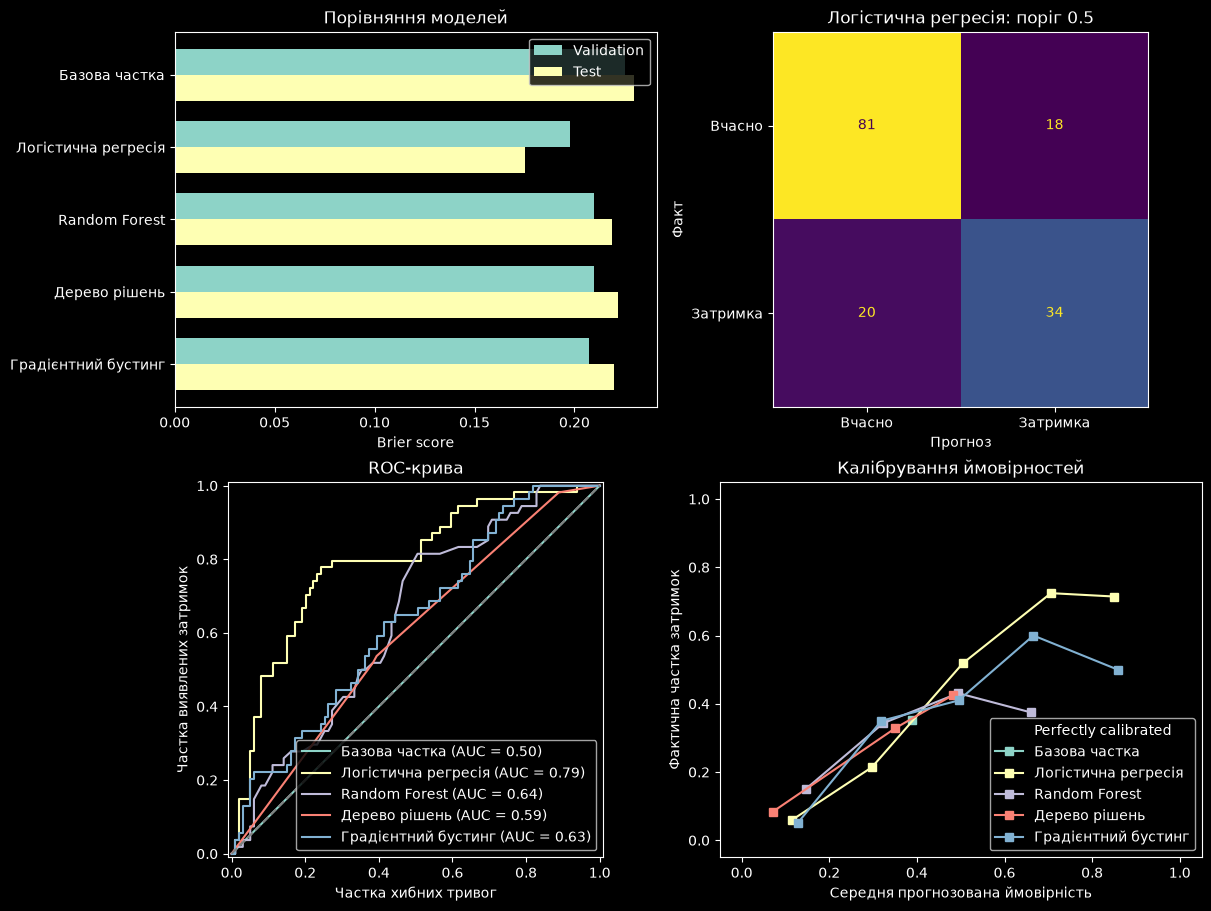

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9), layout="constrained")
names = list(models)
x = np.arange(len(names))
axes[0, 0].barh(x - 0.18, [best[n][1] for n in names], 0.36, label="Validation")
axes[0, 0].barh(x + 0.18, [test_brier[n] for n in names], 0.36, label="Test")
axes[0, 0].set(yticks=x, yticklabels=names, xlabel="Brier score", title="Порівняння моделей")
axes[0, 0].invert_yaxis()
axes[0, 0].legend()

ConfusionMatrixDisplay.from_predictions(
    test_y, predictions[winner] >= THRESHOLD, labels=[0, 1],
    display_labels=["Вчасно", "Затримка"], ax=axes[0, 1], colorbar=False,
)
axes[0, 1].set(title=f"{winner}: поріг {THRESHOLD}", xlabel="Прогноз", ylabel="Факт")

if has_both_classes:
    for name, pred in predictions.items():
        RocCurveDisplay.from_predictions(test_y, pred, name=name, ax=axes[1, 0])
        CalibrationDisplay.from_predictions(test_y, pred, n_bins=5, name=name, ax=axes[1, 1])
    axes[1, 0].plot([0, 1], [0, 1], "--", color="gray")
    axes[1, 0].set(title="ROC-крива", xlabel="Частка хибних тривог", ylabel="Частка виявлених затримок")
    axes[1, 1].set(title="Калібрування ймовірностей", xlabel="Середня прогнозована ймовірність",
                   ylabel="Фактична частка затримок")
else:
    for ax in axes[1]:
        ax.set_axis_off()
        ax.text(0.5, 0.5, "У test є лише один клас", ha="center")
plt.show()

## 4. Перевірка за кількістю послуг
Порівнюй Brier score разом із кількістю спостережень та затримок. Результати на синтетичних замовленнях не підтверджують надійність прогнозу в реальному сервісі.

In [12]:
counts = np.array([row.features["service_count"] for row in test])
pred = predictions[winner]
show_table(["Кількість послуг", "Замовлень у test", "Затримок", f"Brier: {winner}"], [
    (count, int(mask.sum()), int(test_y[mask].sum()),
     f"{brier(test_y[mask], pred[mask]):.3f}" if mask.any() else "—")
    for count in sorted(set(counts) | {1, 2, 3})
    for mask in [counts == count]
])

| Кількість послуг | Замовлень у test | Затримок | Brier: Логістична регресія |
| --- | --- | --- | --- |
| 1 | 121 | 43 | 0.177 |
| 2 | 32 | 11 | 0.167 |
| 3 | 0 | 0 | — |